# Stage 6: Indifference curves and the optimum investor portfolio

Stage 5 picked the best risky portfolio. This stage picks **how much of it an investor should hold**.
That depends on the investor, so we need a way to describe preferences.

## Risk aversion and utility

A standard description is mean-variance utility:

U = E(r) − ½ A σ²

A is the **risk aversion coefficient**. A higher A means each unit of risk costs the investor more.
U is also the **certainty-equivalent return**: the guaranteed return the investor would accept instead
of the risky portfolio.

An **indifference curve** joins all portfolios with the same utility: E(r) = U + ½ A σ². It curves
upward because each extra unit of risk needs more compensation, and steeper curves mean a more
cautious investor. Investors want to reach the highest curve they can.

The optimum is where a curve just touches the available choices. On the line from T-bills through a
fund with return E(r_p) and volatility σ_p, the best share in the fund has an exact answer:

y* = (E(r_p) − r_f) / (A σ_p²)

The profiles below are **illustrative types, not advice for any real person**. All tests use
estimation months only.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from pmo import backtest, models
from pmo import frontier as fr
from pmo import investor as inv
from pmo import returns as ret
from pmo.config import load_config
from pmo.pipeline import load
from pmo.plotting import FIGURES, MUTED, PALETTE, SURFACE, apply_style

apply_style()
config = load_config()
data = load()
stocks = data.universe["symbol"].tolist()
market = config.market_proxy
CAPPED = fr.Constraints(upper=0.10)
HAIRCUT = config.survivorship_haircut

excess = ret.select_period(data.excess, data.periods, "estimation")
RISK_FREE = data.risk_free["rf"].loc[excess.index].mean() * 12


def window_rate(frame):
    return data.risk_free["rf"].loc[frame.index].mean() * 12


def practical(frame):
    premium = data.factors_long.loc[:frame.index.max(), "MKT_RF"].mean()
    return models.practical_inputs(frame[stocks], frame[market], premium)


raw_mean, cov = fr.annualize(*practical(excess), RISK_FREE)
mean = raw_mean - HAIRCUT
fund = fr.solve_max_sharpe(mean, cov, RISK_FREE, CAPPED)
fund_return, fund_vol = fr.portfolio_stats(fund, mean, cov)
print(f"Survivorship haircut {HAIRCUT:.0%}; fund expected return {fund_return:.1%}, "
      f"volatility {fund_vol:.1%}, Sharpe {(fund_return - RISK_FREE) / fund_vol:.2f}")

Survivorship haircut 3%; fund expected return 15.3%, volatility 14.3%, Sharpe 0.62


## 1. An honest expected return

The optimal share is proportional to the expected excess return, so overstating it directly
overstates how much risk an investor should take.

Stage 5 found that a market-like mix of our survivor stocks beat the Nifty by about 6 points a year.
The practical inputs are half historical and half CAPM, and only the historical half carries that
bias. So we take **3 points off every stock's expected return**. This is a judgment-based estimate
rather than a precise measurement, and section 4 shows how much it matters.

## 2. The optimum for three investor types

In [2]:
rows, chosen = [], {}
for profile in inv.PROFILES:
    weights = inv.investor_portfolio(mean, cov, RISK_FREE, profile.risk_aversion, CAPPED)
    chosen[profile.name] = weights
    stock_share = weights.sum()
    expected = float(weights @ mean + (1 - stock_share) * RISK_FREE)
    volatility = fr.portfolio_stats(weights, mean, cov)[1]
    rows.append({"profile": profile.name, "risk_aversion": profile.risk_aversion,
                 "in_stocks": stock_share, "in_tbills": max(1 - stock_share, 0.0),
                 "expected_return": expected, "volatility": volatility,
                 "utility": float(inv.utility(expected, volatility, profile.risk_aversion))})
profiles = pd.DataFrame(rows).set_index("profile")
profiles.round(3)

,risk_aversion,in_stocks,in_tbills,expected_return,volatility,utility
profile,,,,,,
Cautious,8.0,0.543,0.457,0.112,0.078,0.088
Balanced,4.0,1.000,0.000,0.154,0.146,0.112
Growth,2.0,1.000,0.000,0.162,0.162,0.136


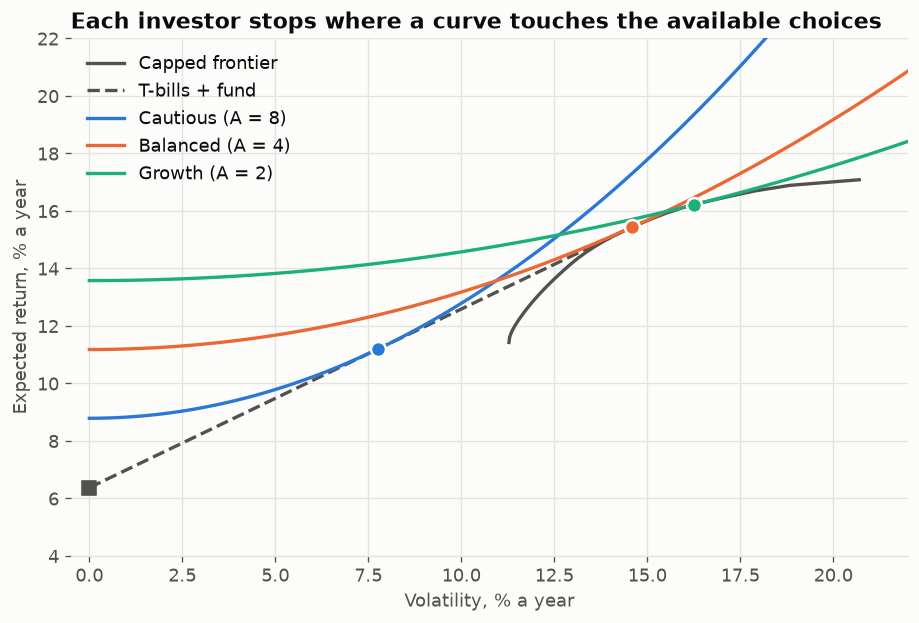

In [3]:
summary, _ = fr.efficient_frontier(mean, cov, CAPPED, points=30)
vol_grid = np.linspace(0, 0.24, 121)

fig, ax = plt.subplots(figsize=(9, 5.6))
ax.grid(axis="x")
ax.plot(summary["volatility"] * 100, summary["expected_return"] * 100, color=MUTED,
        label="Capped frontier")
sharpe = (fund_return - RISK_FREE) / fund_vol
line_vol = np.array([0, fund_vol])
ax.plot(line_vol * 100, fr.capital_market_line(RISK_FREE, sharpe, line_vol) * 100, color=MUTED,
        linestyle="--", label="T-bills + fund")
for profile, color in zip(inv.PROFILES, PALETTE):
    point = profiles.loc[profile.name]
    curve = inv.indifference_curve(point["utility"], vol_grid, profile.risk_aversion)
    ax.plot(vol_grid * 100, curve * 100, color=color, label=f"{profile.name} (A = {profile.risk_aversion:.0f})")
    ax.scatter(point["volatility"] * 100, point["expected_return"] * 100, s=80, color=color,
               edgecolor=SURFACE, linewidth=1.5, zorder=5)
ax.scatter(0, RISK_FREE * 100, s=70, marker="s", color=MUTED, zorder=5)
ax.set_xlim(-0.5, 22)
ax.set_ylim(4, 22)
ax.set_xlabel("Volatility, % a year")
ax.set_ylabel("Expected return, % a year")
ax.set_title("Each investor stops where a curve touches the available choices")
ax.legend(frameon=False, loc="upper left")
fig.savefig(FIGURES / "06_indifference_curves.png")
plt.show()

## 3. Where separation stops working

Two-fund separation says all investors hold the same risky fund. That needs borrowing at the T-bill
rate. Without it, an investor who wants more than a 100% share can't lever up, so they move along
the frontier instead, into a riskier mix of stocks.

Only the first case below is a pure separation result. The table compares each investor's utility
from a T-bill and fund mix with their best fully invested stock portfolio.

In [4]:
rows = {}
for profile in inv.PROFILES:
    share = inv.optimal_risky_share(fund_return, fund_vol, RISK_FREE, profile.risk_aversion)
    mix = float(inv.utility(RISK_FREE + share * (fund_return - RISK_FREE), share * fund_vol,
                            profile.risk_aversion))
    stocks_only = inv.optimal_on_frontier(mean, cov, profile.risk_aversion, CAPPED)
    only_return, only_vol = fr.portfolio_stats(stocks_only, mean, cov)
    rows[profile.name] = {
        "uncapped_share_wanted": (fund_return - RISK_FREE) / (profile.risk_aversion * fund_vol ** 2),
        "utility_mix": mix,
        "utility_stocks_only": float(inv.utility(only_return, only_vol, profile.risk_aversion))}
pd.DataFrame(rows).T.round(3)

,uncapped_share_wanted,utility_mix,utility_stocks_only
Cautious,0.543,0.088,0.075
Balanced,1.086,0.112,0.112
Growth,2.172,0.132,0.136


## 4. How sensitive is the answer?

This recomputes the optimal share under different survivorship haircuts, and with leverage available
at the illustrative 10% borrowing rate.

In [5]:
rows = {}
for haircut in [0.0, 0.03, 0.06]:
    trial = raw_mean - haircut
    trial_fund = fr.solve_max_sharpe(trial, cov, RISK_FREE, CAPPED)
    expected, volatility = fr.portfolio_stats(trial_fund, trial, cov)
    for profile in inv.PROFILES:
        rows[f"{haircut:.0%} haircut", profile.name] = {
            "no_borrowing": inv.optimal_risky_share(expected, volatility, RISK_FREE,
                                                    profile.risk_aversion),
            "borrow_at_10pct": inv.optimal_risky_share(expected, volatility, RISK_FREE,
                                                       profile.risk_aversion, borrow_rate=0.10,
                                                       max_share=2.0)}
pd.DataFrame(rows).T.round(2)

no_borrowing  borrow_at_10pct
0% haircut Cautious          0.78             0.78
           Balanced          1.00             1.06
           Growth            1.00             2.00
3% haircut Cautious          0.54             0.54
           Balanced          1.00             1.00
           Growth            1.00             1.29
6% haircut Cautious          0.33             0.33
           Balanced          0.67             0.67
           Growth            1.00             1.00

The share moves a lot with the assumed return, which is itself uncertain by several points. So
treat it as a rough range rather than a precise figure, especially for cautious investors.

## 5. Which share would have worked?

This tests the choice on later data. Using the walk-forward capped fund from Stage 5, we measure the
**realized certainty-equivalent excess return** at every share, for each investor. Higher is better
for that investor. Costs are excluded, and the holdout remains untouched.

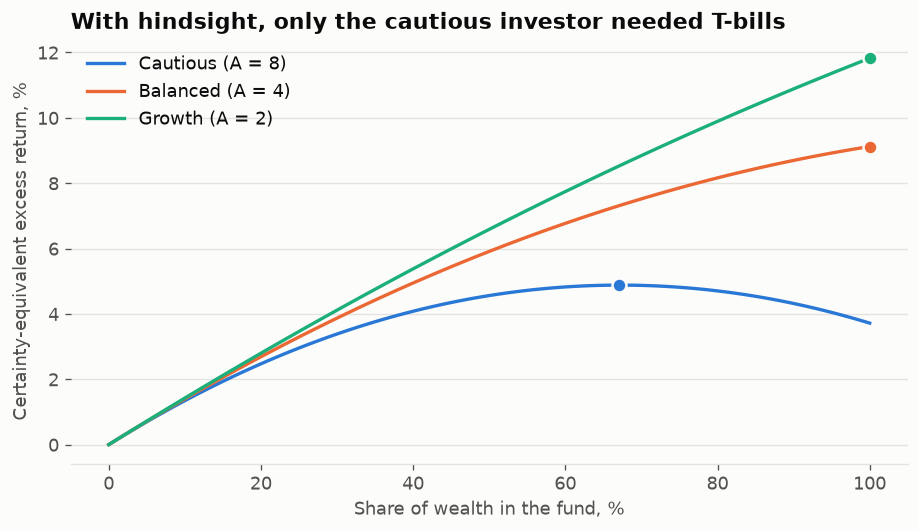

Best share with hindsight, 60-month window: {'Cautious': 0.67, 'Balanced': 1.0, 'Growth': 1.0}


In [6]:
def fund_strategy(train):
    rate = window_rate(train)
    train_mean, train_cov = fr.annualize(*practical(train), rate)
    return fr.solve_max_sharpe(train_mean - HAIRCUT, train_cov, rate, CAPPED)


def profile_strategy(aversion):
    def build(train):
        rate = window_rate(train)
        train_mean, train_cov = fr.annualize(*practical(train), rate)
        return inv.investor_portfolio(train_mean - HAIRCUT, train_cov, rate, aversion, CAPPED)
    return build


strategies = {"Fund": fund_strategy}
strategies.update({p.name: profile_strategy(p.risk_aversion) for p in inv.PROFILES})
long_window = backtest.run(excess, strategies, window=60, step=12)
short_window = backtest.run(excess, strategies, window=36, step=12)

fund_mean, fund_sd = long_window.returns["Fund"].mean() * 12, long_window.returns["Fund"].std() * np.sqrt(12)
shares = np.linspace(0, 1, 101)
fig, ax = plt.subplots(figsize=(9, 4.6))
best = {}
for profile, color in zip(inv.PROFILES, PALETTE):
    ce = inv.utility(shares * fund_mean, shares * fund_sd, profile.risk_aversion)
    best[profile.name] = shares[ce.argmax()]
    ax.plot(shares * 100, ce * 100, color=color, label=f"{profile.name} (A = {profile.risk_aversion:.0f})")
    ax.scatter(shares[ce.argmax()] * 100, ce.max() * 100, s=70, color=color, edgecolor=SURFACE,
               linewidth=1.5, zorder=5)
ax.set_xlabel("Share of wealth in the fund, %")
ax.set_ylabel("Certainty-equivalent excess return, %")
ax.set_title("With hindsight, only the cautious investor needed T-bills")
ax.legend(frameon=False, loc="upper left")
fig.savefig(FIGURES / "06_realized_share.png")
plt.show()
print("Best share with hindsight, 60-month window:", {k: round(float(v), 2) for k, v in best.items()})

### Re-estimating the share every year, or keeping it fixed?

Estimates change each year, so a re-estimated share acts like market timing based on noisy inputs.
This compares it with holding one fixed share, for the cautious investor. The fixed share comes from
section 2, so that single number uses all estimation months.

In [7]:
cautious = next(p for p in inv.PROFILES if p.name == "Cautious")
fixed_share = float(profiles.loc["Cautious", "in_stocks"])
rows = []
for label, result in [("60-month window", long_window), ("36-month window", short_window)]:
    held = result.returns["Cautious"]
    fixed = result.returns["Fund"] * fixed_share
    for name, series in [("Re-estimated yearly", held), ("Fixed share", fixed)]:
        mean_excess, sd = series.mean() * 12, series.std() * np.sqrt(12)
        rows.append({"window": label, "method": name, "excess_return": mean_excess,
                     "volatility": sd, "max_drawdown": backtest.stats.max_drawdown(series),
                     "realized_ce": float(inv.utility(mean_excess, sd, cautious.risk_aversion))})
print(f"Fixed share: {fixed_share:.0%}")
timing = pd.DataFrame(rows).set_index(["window", "method"])
timing.round(3)

Fixed share: 54%


excess_return  volatility  max_drawdown  \
window          method                                                         
60-month window Re-estimated yearly          0.093       0.107        -0.117   
                Fixed share                  0.079       0.089        -0.107   
36-month window Re-estimated yearly          0.104       0.133        -0.190   
                Fixed share                  0.076       0.086        -0.105   

                                     realized_ce  
window          method                            
60-month window Re-estimated yearly        0.048  
                Fixed share                0.047  
36-month window Re-estimated yearly        0.033  
                Fixed share                0.046

In [8]:
rows = {}
for label, result in [("60-month window", long_window), ("36-month window", short_window)]:
    for profile in inv.PROFILES:
        series = result.returns[profile.name]
        mean_excess, sd = series.mean() * 12, series.std() * np.sqrt(12)
        rows[label, profile.name] = {
            "average_stock_share": result.weights[profile.name].sum(axis=1).mean(),
            "excess_return": mean_excess, "volatility": sd,
            "sharpe": mean_excess / sd,
            "max_drawdown": backtest.stats.max_drawdown(series),
            "realized_ce": float(inv.utility(mean_excess, sd, profile.risk_aversion)),
            "fund_ce": float(inv.utility(result.returns["Fund"].mean() * 12,
                                         result.returns["Fund"].std() * np.sqrt(12),
                                         profile.risk_aversion))}
pd.DataFrame(rows).T.round(3)

average_stock_share  excess_return  volatility  \
60-month window Cautious                0.659          0.093       0.107   
                Balanced                0.987          0.152       0.169   
                Growth                  1.000          0.158       0.175   
36-month window Cautious                0.737          0.104       0.133   
                Balanced                0.977          0.144       0.161   
                Growth                  1.000          0.150       0.170   

                          sharpe  max_drawdown  realized_ce  fund_ce  
60-month window Cautious   0.876        -0.117        0.048    0.037  
                Balanced   0.899        -0.200        0.095    0.091  
                Growth     0.901        -0.209        0.127    0.118  
36-month window Cautious   0.778        -0.190        0.033    0.039  
                Balanced   0.892        -0.199        0.092    0.090  
                Growth     0.881        -0.199        0.121    0.115

## 6. From a questionnaire to a portfolio

This is a first version of the logic for the final tool. Utility alone is a weak guide, for two
reasons: people find A hard to state, and a share near 100% can still mean a loss they couldn't live
with. So the tool should combine two inputs and use the **lower** of the two results:

1. **Willingness to take risk:** a questionnaire score from 0 to 1, mapped to A from 10 down to 1.5.
2. **Tolerated loss:** the largest fall the investor says they could sit through. This caps the share
   so that a repeat of 2008, when the Nifty fell 60%, stays within that limit.

The table works through both. The 60% stress loss is a historical figure for the index, not a limit
on how far a portfolio can fall.

In [9]:
rows = []
for score in [0.0, 0.25, 0.5, 0.75, 1.0]:
    aversion = inv.aversion_from_score(score)
    share = inv.optimal_risky_share(fund_return, fund_vol, RISK_FREE, aversion)
    row = {"score": score, "risk_aversion": aversion, "share_from_score": share}
    for loss in [0.10, 0.20, 0.30, 0.50]:
        limit = inv.loss_limited_share(loss, config.stress_loss)
        row[f"final_if_{loss:.0%}_loss_ok"] = min(share, limit)
    rows.append(row)
pd.DataFrame(rows).set_index("score").round(2)

,risk_aversion,share_from_score,final_if_10%_loss_ok,final_if_20%_loss_ok,final_if_30%_loss_ok,final_if_50%_loss_ok
score,,,,,,
0.00,10.00,0.43,0.17,0.33,0.43,0.43
0.25,6.22,0.70,0.17,0.33,0.50,0.70
0.50,3.87,1.00,0.17,0.33,0.50,0.83
0.75,2.41,1.00,0.17,0.33,0.50,0.83
1.00,1.50,1.00,0.17,0.33,0.50,0.83


### A worked example

An illustrative ₹10,00,000 split for each profile. The whole-share rounding comes in Stage 11.

In [10]:
AMOUNT = 1_000_000
rows = {}
for profile in inv.PROFILES:
    weights = chosen[profile.name]
    rows[profile.name] = {"T-bills (₹)": max(1 - weights.sum(), 0.0) * AMOUNT,
                          "Stocks (₹)": weights.sum() * AMOUNT,
                          "Stocks held": int((weights > 0.001).sum()),
                          "Largest stock (₹)": weights.max() * AMOUNT}
pd.DataFrame(rows).T.round(0)

,T-bills (₹),Stocks (₹),Stocks held,Largest stock (₹)
Cautious,457061.0,542939.0,14.0,54294.0
Balanced,0.0,1000000.0,14.0,100000.0
Growth,0.0,1000000.0,11.0,100000.0


## Stage 6 conclusions

1. **Risk aversion sets the mix, not the stocks:** below a 100% share, investors differ only in their
   T-bill and fund split, as separation predicts.
2. **Separation stops at 100%:** without cheap borrowing, bolder investors move up the frontier into a
   riskier stock mix.
3. **The share depends heavily on the assumed return:** the survivorship haircut alone moves it
   substantially for cautious investors.
4. **A fixed share is the safer policy:** it tied on the 60-month window and clearly won on the
   36-month window, with about half the drawdown, because yearly re-estimates add timing noise.
5. **Utility is not enough:** the tool should also cap the share by the loss an investor can accept.

The expected returns here are model estimates, and these are illustrative profiles. Nothing here is
personal investment advice.